Number of images: 202599

Epoch 1/20


C:\Users\HP\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1583/1583 ━━━━━━━━━━━━━━━━━━━━ 80s 46ms/step - kl_loss: 6.0645 - loss: 1407.0420 - reconstruction_loss: 1400.9774
Epoch 2/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 74s 45ms/step - kl_loss: 5.9336 - loss: 1380.5280 - reconstruction_loss: 1374.5944
Epoch 3/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 409s 256ms/step - kl_loss: 5.8882 - loss: 1379.6062 - reconstruction_loss: 1373.7180
Epoch 4/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 75s 45ms/step - kl_loss: 5.7967 - loss: 1370.5951 - reconstruction_loss: 1364.7983
Epoch 5/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 76s 46ms/step - kl_loss: 6.1579 - loss: 1341.0665 - reconstruction_loss: 1334.9087
Epoch 6/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 173s 107ms/step - kl_loss: 5.6179 - loss: 1401.0192 - reconstruction_loss: 1395.4012
Epoch 7/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 77s 47ms/step - kl_loss: 6.1162 - loss: 1355.6648 - reconstruction_loss: 1349.5486
Epoch 8/20
1583/1583 ━━━━━━━━━━━━━━━━━━━━ 75s 45ms/step - kl_loss: 5.6652 - loss: 1369.7256 - reconstruction_loss: 1364.0604
Epoch 9

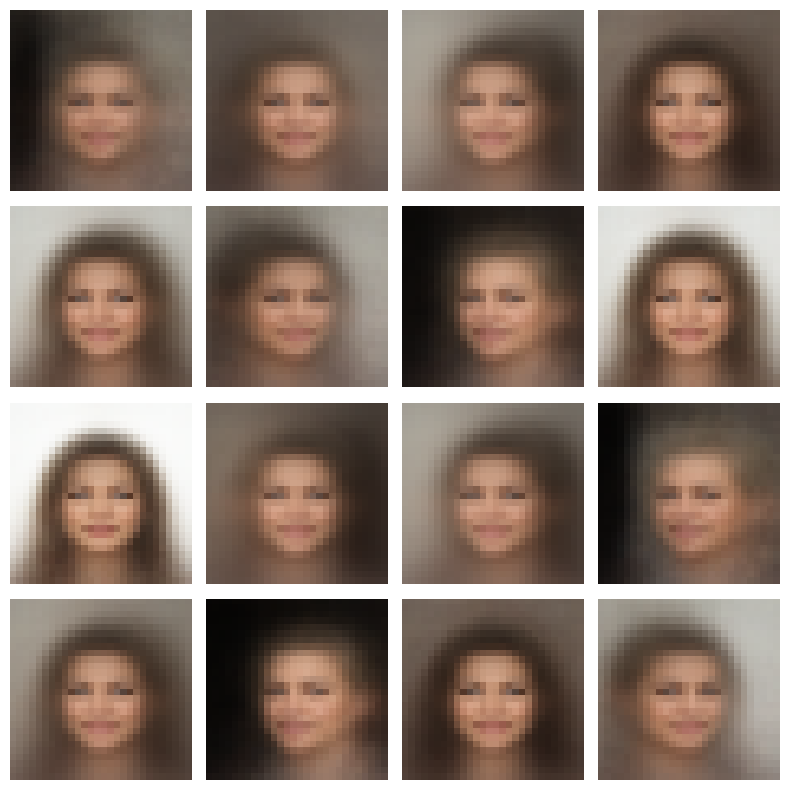

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. PARAMETERS
# ============================================================

IMAGE_SIZE = 28
CHANNELS = 3

INPUT_DIM = IMAGE_SIZE * IMAGE_SIZE * CHANNELS

LATENT_DIM = 2
HIDDEN_DIM = 256
BATCH_SIZE = 128
EPOCHS = 20


# ============================================================
# 2. LOAD CELEBRITY IMAGE FILES
# ============================================================

IMAGE_FOLDER = r"C:\Users\HP\celeba\data\img_align_celeba\img_align_celeba"

image_files = [
    os.path.join(IMAGE_FOLDER, file)
    for file in os.listdir(IMAGE_FOLDER)
    if file.lower().endswith(".jpg")
]

print("Number of images:", len(image_files))


# ============================================================
# 3. CREATE TENSORFLOW DATASET
# ============================================================

train_dataset = tf.data.Dataset.from_tensor_slices(
    image_files
)


# ============================================================
# 4. PREPROCESS IMAGES
# ============================================================

def preprocess_image(file_path):

    # Read image
    image = tf.io.read_file(file_path)

    # Decode JPEG
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize to 28 × 28
    image = tf.image.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    # Normalize pixels
    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    # Flatten 28 × 28 × 3
    image = tf.reshape(
        image,
        (INPUT_DIM,)
    )

    return image


train_dataset = train_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.shuffle(
    10000
)

train_dataset = train_dataset.batch(
    BATCH_SIZE
)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)


# ============================================================
# 5. ENCODER
# ============================================================

encoder_inputs = tf.keras.Input(
    shape=(INPUT_DIM,),
    name="encoder_input"
)

x = tf.keras.layers.Dense(
    HIDDEN_DIM,
    activation="relu"
)(encoder_inputs)

z_mean = tf.keras.layers.Dense(
    LATENT_DIM,
    name="z_mean"
)(x)

z_log_var = tf.keras.layers.Dense(
    LATENT_DIM,
    name="z_log_var"
)(x)


# ============================================================
# 6. REPARAMETERIZATION / SAMPLING
# ============================================================

def sampling(args):

    z_mean, z_log_var = args

    epsilon = tf.random.normal(
        shape=tf.shape(z_mean)
    )

    z = (
        z_mean
        + tf.exp(0.5 * z_log_var) * epsilon
    )

    return z


z = tf.keras.layers.Lambda(
    sampling,
    name="latent_vector"
)([
    z_mean,
    z_log_var
])


# ============================================================
# 7. CREATE ENCODER
# ============================================================

encoder = tf.keras.Model(
    encoder_inputs,
    [
        z_mean,
        z_log_var,
        z
    ],
    name="encoder"
)


# ============================================================
# 8. DECODER
# ============================================================

latent_inputs = tf.keras.Input(
    shape=(LATENT_DIM,),
    name="decoder_input"
)

x = tf.keras.layers.Dense(
    HIDDEN_DIM,
    activation="relu"
)(latent_inputs)

decoder_outputs = tf.keras.layers.Dense(
    INPUT_DIM,
    activation="sigmoid"
)(x)

decoder = tf.keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)


# ============================================================
# 9. VAE MODEL
# ============================================================

class VAE(tf.keras.Model):

    def __init__(
        self,
        encoder,
        decoder,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        with tf.GradientTape() as tape:

            # Encode input
            z_mean, z_log_var, z = self.encoder(data)

            # Decode latent vector
            reconstruction = self.decoder(z)

            # ----------------------------------------------
            # Reconstruction loss
            # ----------------------------------------------

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    -(
                        data * tf.math.log(
                            reconstruction + 1e-7
                        )
                        +
                        (1 - data) * tf.math.log(
                            1 - reconstruction + 1e-7
                        )
                    ),
                    axis=1
                )
            )

            # ----------------------------------------------
            # KL divergence
            # ----------------------------------------------

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            # ----------------------------------------------
            # Total loss
            # ----------------------------------------------

            total_loss = (
                reconstruction_loss
                + kl_loss
            )

        # Calculate gradients
        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        # Update weights
        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }


# ============================================================
# 10. CREATE VAE
# ============================================================

vae = VAE(
    encoder,
    decoder
)


# ============================================================
# 11. COMPILE
# ============================================================

vae.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
)


# ============================================================
# 12. TRAIN VAE
# ============================================================

vae.fit(
    train_dataset,
    epochs=EPOCHS
)


# ============================================================
# 13. GENERATE NEW CELEBRITY FACES
# ============================================================

number_of_images = 16

random_latent_vectors = tf.random.normal(
    shape=(
        number_of_images,
        LATENT_DIM
    )
)

generated_images = decoder(
    random_latent_vectors
)


# ============================================================
# 14. DISPLAY GENERATED CELEBRITY FACES
# ============================================================

plt.figure(
    figsize=(8, 8)
)

for i in range(number_of_images):

    ax = plt.subplot(
        4,
        4,
        i + 1
    )

    image = generated_images[i].numpy()

    image = image.reshape(
        IMAGE_SIZE,
        IMAGE_SIZE,
        CHANNELS
    )

    plt.imshow(image)

    plt.axis("off")

plt.tight_layout()
plt.show()